# Phân tích dữ liệu bán lẻ trực tuyến — Online Retail II (UCI)




## 0. Cài đặt và import thư viện




In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
sns.set_theme(style='whitegrid')


---
# GIAI ĐOẠN 1 — Thu thập & đánh giá dữ liệu ban đầu

## 1.1 Nguồn dữ liệu
- **Nguồn:** Kaggle — *Online Retail Dataset* (bản gốc: UCI Machine Learning Repository, *Online Retail II*).
- **File:** `online_retail_II.xlsx` gồm **2 sheet**: `Year 2009-2010` và `Year 2010-2011`, cùng cấu trúc 8 cột.
- **Đơn vị quan sát:** mỗi dòng là **một dòng sản phẩm trong một hóa đơn**.

| Thuộc tính | Ý nghĩa |
|---|---|
| `Invoice` | Mã hóa đơn (6 chữ số). Bắt đầu bằng **C** = hóa đơn hủy/trả hàng |
| `StockCode` | Mã sản phẩm (5 chữ số, có thể kèm chữ cái) |
| `Description` | Tên sản phẩm |
| `Quantity` | Số lượng mỗi sản phẩm trên hóa đơn |
| `InvoiceDate` | Thời điểm lập hóa đơn |
| `Price` | Đơn giá (GBP £) |
| `Customer ID` | Mã khách hàng (5 chữ số) |
| `Country` | Quốc gia của khách hàng |

In [ ]:
# Đường dẫn dữ liệu: đặt file cùng thư mục với notebook,
# hoặc thay bằng link raw GitHub / Google Drive của nhóm
DATA_PATH = 'online_retail_II.xlsx'

# Trên Colab: nếu chưa có file thì mở hộp thoại upload
if not os.path.exists(DATA_PATH):
    try:
        from google.colab import files
        uploaded = files.upload()
        DATA_PATH = list(uploaded.keys())[0]
    except ImportError:
        raise FileNotFoundError('Không tìm thấy file online_retail_II.xlsx')

In [ ]:
# Đọc cả 2 sheet (sheet_name=None trả về dict {tên sheet: DataFrame})
sheets = pd.read_excel(DATA_PATH, sheet_name=None, dtype={'Invoice': str, 'StockCode': str})
for name, d in sheets.items():
    print(f'{name:16s}: {d.shape[0]:>9,} dòng x {d.shape[1]} cột | '
          f'{d.InvoiceDate.min():%d/%m/%Y} → {d.InvoiceDate.max():%d/%m/%Y}')

Year 2009-2010  :   525,461 dòng x 8 cột | 01/12/2009 → 09/12/2010
Year 2010-2011  :   541,910 dòng x 8 cột | 01/12/2010 → 09/12/2011


## 1.2 Kiểm tra tính nhất quán giữa 2 file (sheet) trước khi gộp

In [ ]:
# Kiểm tra 1: hai sheet có cùng tên cột và kiểu dữ liệu không?
s1, s2 = sheets['Year 2009-2010'], sheets['Year 2010-2011']
print('Cùng tên cột   :', list(s1.columns) == list(s2.columns))
print('Cùng kiểu dữ liệu:', (s1.dtypes == s2.dtypes).all())

# Kiểm tra 2: khoảng thời gian 2 sheet có chồng lấn không? (nguy cơ trùng lặp khi gộp)
overlap_start, overlap_end = s2.InvoiceDate.min(), s1.InvoiceDate.max()
print(f'\nKhoảng chồng lấn: {overlap_start:%d/%m/%Y} → {overlap_end:%d/%m/%Y}')
ov1 = s1[s1.InvoiceDate >= overlap_start]
ov2 = s2[s2.InvoiceDate <= overlap_end]
print(f'Số dòng trong khoảng chồng lấn: sheet1 = {len(ov1):,} | sheet2 = {len(ov2):,}')
common_inv = set(ov1.Invoice) & set(ov2.Invoice)
print(f'Số hóa đơn xuất hiện ở CẢ 2 sheet: {len(common_inv):,}')

Cùng tên cột   : True
Cùng kiểu dữ liệu: True

Khoảng chồng lấn: 01/12/2010 → 09/12/2010
Số dòng trong khoảng chồng lấn: sheet1 = 22,523 | sheet2 = 22,523
Số hóa đơn xuất hiện ở CẢ 2 sheet: 1,088


In [ ]:
# Kiểm tra 3: khách hàng & sản phẩm có xuất hiện xuyên suốt 2 năm không? (khóa liên kết)
c1, c2 = set(s1['Customer ID'].dropna()), set(s2['Customer ID'].dropna())
p1, p2 = set(s1.StockCode), set(s2.StockCode)
print(f'Khách hàng: sheet1 = {len(c1):,}, sheet2 = {len(c2):,}, chung = {len(c1 & c2):,}')
print(f'Sản phẩm  : sheet1 = {len(p1):,}, sheet2 = {len(p2):,}, chung = {len(p1 & p2):,}')

Khách hàng: sheet1 = 4,383, sheet2 = 4,372, chung = 2,813
Sản phẩm  : sheet1 = 4,632, sheet2 = 4,070, chung = 3,397


In [ ]:
# Gộp 2 sheet thành 1 DataFrame
df_raw = pd.concat(sheets.values(), ignore_index=True)
print('Kích thước sau khi gộp:', df_raw.shape)
df_raw.head()

Kích thước sau khi gộp: (1067371, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom


## 1.3 Rà soát cấu trúc & kiểu dữ liệu

In [ ]:
# Thông tin kiểu dữ liệu từng trường
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[ns]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 65.1+ MB


In [ ]:
# Thống kê mô tả các biến số
df_raw.describe().T

,count,mean,min,25%,50%,75%,max,std
Quantity,"1,067,371.00",9.94,"-80,995.00",1.00,3.00,10.00,"80,995.00",172.71
InvoiceDate,1067371,2011-01-02 21:13:55.394028544,2009-12-01 07:45:00,2010-07-09 09:46:00,2010-12-07 15:28:00,2011-07-22 10:23:00,2011-12-09 12:50:00,NaN
Price,"1,067,371.00",4.65,"-53,594.36",1.25,2.10,4.15,"38,970.00",123.55
Customer ID,"824,364.00","15,324.64","12,346.00","13,975.00","15,255.00","16,797.00","18,287.00","1,697.46"


## 1.4 Tỷ lệ giá trị khuyết thiếu (missing values)

,Số lượng thiếu,Tỷ lệ (%)
Customer ID,243007,22.77
Description,4382,0.41
StockCode,0,0.00
Invoice,0,0.00
Quantity,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
Country,0,0.00


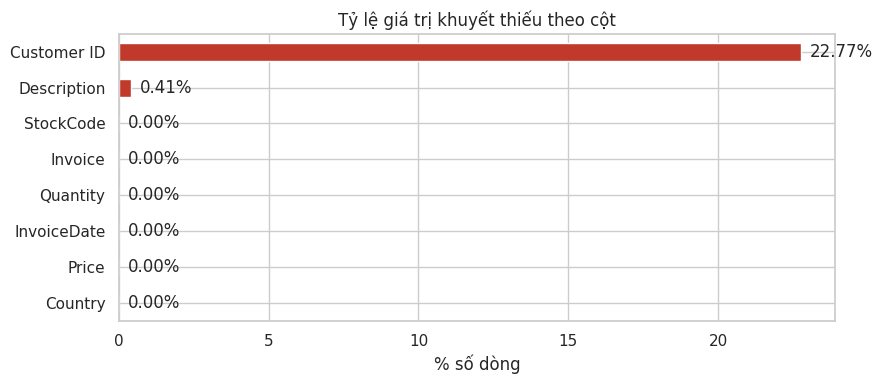

In [ ]:
# Đếm và tính tỷ lệ missing từng cột
miss = pd.DataFrame({'Số lượng thiếu': df_raw.isna().sum(),
                     'Tỷ lệ (%)': df_raw.isna().mean() * 100}).sort_values('Tỷ lệ (%)', ascending=False)
display(miss)

fig, ax = plt.subplots(figsize=(9, 4))
miss['Tỷ lệ (%)'].plot.barh(ax=ax, color=['#c0392b' if v > 0 else '#95a5a6' for v in miss['Tỷ lệ (%)']])
ax.set_title('Tỷ lệ giá trị khuyết thiếu theo cột'); ax.set_xlabel('% số dòng')
for i, v in enumerate(miss['Tỷ lệ (%)']):
    ax.text(v + 0.3, i, f'{v:.2f}%', va='center')
ax.invert_yaxis(); plt.tight_layout(); plt.show()

In [ ]:
# Missing Customer ID có phân bố ngẫu nhiên không? So sánh theo quốc gia & loại hóa đơn
tmp = df_raw.assign(missing_id=df_raw['Customer ID'].isna())
print('Tỷ lệ thiếu Customer ID — UK vs ngoài UK:')
print(tmp.groupby(tmp.Country.eq('United Kingdom').map({True: 'UK', False: 'Ngoài UK'}))['missing_id'].mean().mul(100).round(2))
print('\nĐơn giá trung bình: có ID vs thiếu ID')
print(tmp.groupby('missing_id')['Price'].median())

Tỷ lệ thiếu Customer ID — UK vs ngoài UK:
Country
Ngoài UK    3.46
UK         24.46
Name: missing_id, dtype: float64

Đơn giá trung bình: có ID vs thiếu ID
missing_id
False   1.95
True    3.29
Name: Price, dtype: float64


## 1.5 Các vấn đề chất lượng dữ liệu khác

In [ ]:
# Đếm các dạng dữ liệu bất thường để lên kế hoạch làm sạch
inv = df_raw.Invoice.astype(str)
checks = {
    'Dòng trùng lặp hoàn toàn'           : df_raw.duplicated().sum(),
    'Hóa đơn hủy (Invoice bắt đầu bằng C)': inv.str.startswith('C').sum(),
    'Hóa đơn điều chỉnh nợ (bắt đầu bằng A)': inv.str.startswith('A').sum(),
    'Quantity <= 0'                       : (df_raw.Quantity <= 0).sum(),
    'Price <= 0'                          : (df_raw.Price <= 0).sum(),
    'StockCode không phải sản phẩm (POST, M, DOT, ...)': df_raw.StockCode.astype(str).str.match(r'^[A-Za-z_ ]+$|^(DCGS|gift)', case=False).sum(),
}
pd.Series(checks, name='Số dòng').to_frame()

,Số dòng
Dòng trùng lặp hoàn toàn,34335
Hóa đơn hủy (Invoice bắt đầu bằng C),19494
Hóa đơn điều chỉnh nợ (bắt đầu bằng A),6
Quantity <= 0,22950
Price <= 0,6207
"StockCode không phải sản phẩm (POST, M, DOT, ...)",5787


In [ ]:
# Các mã StockCode chỉ gồm chữ cái — là phí/điều chỉnh chứ không phải hàng hóa
non_prod = df_raw[df_raw.StockCode.astype(str).str.match(r'^[A-Za-z_ ]+$|^(DCGS|gift)', case=False)]
non_prod.groupby('StockCode').agg(so_dong=('Invoice', 'size'), mo_ta=('Description', 'first')).sort_values('so_dong', ascending=False).head(12)

,so_dong,mo_ta
StockCode,,
POST,2122,POSTAGE
DOT,1446,DOTCOM POSTAGE
M,1421,Manual
D,177,Discount
S,104,SAMPLES
BANK CHARGES,102,Bank Charges
ADJUST,67,Adjustment by john on 26/01/2010 16
AMAZONFEE,43,AMAZON FEE
DCGS0058,31,MISO PRETTY GUM


In [ ]:
# Một StockCode có nhiều Description khác nhau không? (nhất quán khóa sản phẩm)
n_desc = df_raw.dropna(subset=['Description']).groupby('StockCode').Description.nunique()
print(f'Số StockCode có > 1 mô tả: {(n_desc > 1).sum():,} / {len(n_desc):,}')
df_raw[df_raw.StockCode == n_desc.idxmax()].Description.value_counts().head()

Số StockCode có > 1 mô tả: 1,232 / 4,950


,count
Description,
JUMBO BAG OWLS,1372
missing,1
wrongly marked. 23343 in box,1
wrongly coded-23343,1
found,1


---
# GIAI ĐOẠN 2 — Tiền xử lý và làm sạch dữ liệu


| Vấn đề | Cách xử lý | Lý do và lưu ý |
|---|---|---|
| Trùng hoàn toàn | `drop_duplicates()` | Tránh đếm trùng; có thể có các dòng giao dịch giống nhau thật, nên ghi rõ giả định này |
| Hóa đơn bắt đầu bằng C | Tách bảng `df_cancel` | Phân tích riêng hủy/trả; không cộng vào doanh thu bán hàng dương |
| Mã phí/điều chỉnh | Tách khỏi phân tích sản phẩm | Không phải mặt hàng bán thông thường; cần ghi nhận đây là quy tắc lọc gần đúng |
| Quantity ≤ 0, Price ≤ 0 | Loại khỏi bảng doanh thu bán hàng | Không phản ánh dòng bán hàng có giá trị dương; không có nghĩa dữ liệu gốc sai |
| Description thiếu | Điền bằng mô tả phổ biến nhất cùng StockCode | Không tự suy đoán tên sản phẩm khác mã |
| Customer ID thiếu | Giữ trong bảng doanh thu; bỏ khỏi phân tích theo khách | Mã định danh không thể thay bằng trung bình hoặc mode |
| Ngoại lệ | Dùng IQR để **phát hiện**, kiểm tra trước khi loại | Đơn sỉ lớn có thể hợp lệ; không xóa máy móc mọi outlier |

**Hạn chế quan trọng:** Không có liên kết hoàn chỉnh giữa hóa đơn trả và đơn gốc, nên các tỷ lệ hủy chỉ mang tính chỉ báo, không phải tỷ lệ hoàn trả chính xác theo từng đơn gốc.


In [ ]:
# Bước 1: xóa dòng trùng lặp hoàn toàn
df = df_raw.copy()
n0 = len(df)
df = df.drop_duplicates()
print(f'Đã xóa {n0 - len(df):,} dòng trùng lặp ({(n0 - len(df)) / n0:.2%})')

# Chuẩn hóa kiểu dữ liệu: Invoice/StockCode là chuỗi, Customer ID là chuỗi định danh (không phải số để tính toán)
df['Invoice'] = df['Invoice'].astype(str)
df['StockCode'] = df['StockCode'].astype(str).str.upper().str.strip()
df['Customer ID'] = df['Customer ID'].astype('Int64').astype(str).replace('<NA>', np.nan)
df['Description'] = df['Description'].astype('string').str.strip()

Đã xóa 34,335 dòng trùng lặp (3.22%)


In [ ]:
# Bước 2: tách hóa đơn hủy sang bảng riêng
is_cancel = df.Invoice.str.startswith('C')
df_cancel = df[is_cancel].copy()
df = df[~is_cancel & ~df.Invoice.str.startswith('A')]   # bỏ luôn hóa đơn điều chỉnh nợ 'A'
print(f'Hóa đơn hủy: {df_cancel.Invoice.nunique():,} hóa đơn | {len(df_cancel):,} dòng')

Hóa đơn hủy: 8,292 hóa đơn | 19,104 dòng


In [ ]:
# Bước 3: loại các mã không phải sản phẩm
non_product = df.StockCode.str.match(r'^[A-Z_ ]+$|^(DCGS|GIFT)')
print('Loại các mã:', sorted(df.loc[non_product, 'StockCode'].unique()))
df = df[~non_product]

# Bước 4: loại Price <= 0 và Quantity <= 0
n1 = len(df)
df = df[(df.Price > 0) & (df.Quantity > 0)]
print(f'Loại {n1 - len(df):,} dòng có Price hoặc Quantity <= 0')

Loại các mã: ['ADJUST', 'AMAZONFEE', 'BANK CHARGES', 'D', 'DCGS0003', 'DCGS0004', 'DCGS0006', 'DCGS0016', 'DCGS0027', 'DCGS0036', 'DCGS0037', 'DCGS0039', 'DCGS0041', 'DCGS0044', 'DCGS0053', 'DCGS0055', 'DCGS0056', 'DCGS0057', 'DCGS0058', 'DCGS0059', 'DCGS0060', 'DCGS0062', 'DCGS0066N', 'DCGS0066P', 'DCGS0067', 'DCGS0068', 'DCGS0069', 'DCGS0070', 'DCGS0071', 'DCGS0072', 'DCGS0073', 'DCGS0074', 'DCGS0075', 'DCGS0076', 'DCGSLBOY', 'DCGSLGIRL', 'DCGSSBOY', 'DCGSSGIRL', 'DOT', 'GIFT', 'GIFT_0001_10', 'GIFT_0001_20', 'GIFT_0001_30', 'GIFT_0001_40', 'GIFT_0001_50', 'GIFT_0001_60', 'GIFT_0001_70', 'GIFT_0001_80', 'GIFT_0001_90', 'M', 'PADS', 'POST', 'S']
Loại 5,936 dòng có Price hoặc Quantity <= 0


In [ ]:
# Bước 5: điền Description thiếu bằng mode của cùng StockCode
mode_desc = df.dropna(subset=['Description']).groupby('StockCode').Description.agg(lambda s: s.mode().iat[0])
before = df.Description.isna().sum()
df['Description'] = df.Description.fillna(df.StockCode.map(mode_desc))
# Đồng thời chuẩn hóa: mỗi StockCode dùng 1 tên duy nhất (tên phổ biến nhất)
df['Description'] = df.StockCode.map(mode_desc).fillna(df.Description)
print(f'Description thiếu: dữ liệu gốc {df_raw.Description.isna().sum():,} → trước bước này {before:,} → sau khi điền {df.Description.isna().sum():,}')
print('Các dòng thiếu Description trong dữ liệu gốc có Price = 0:', (df_raw.loc[df_raw.Description.isna(), 'Price'] == 0).mean() * 100, '%')

Description thiếu: dữ liệu gốc 4,382 → trước bước này 0 → sau khi điền 0
Các dòng thiếu Description trong dữ liệu gốc có Price = 0: 100.0 %


## 2.1 Phát hiện & xử lý ngoại lệ (outliers)

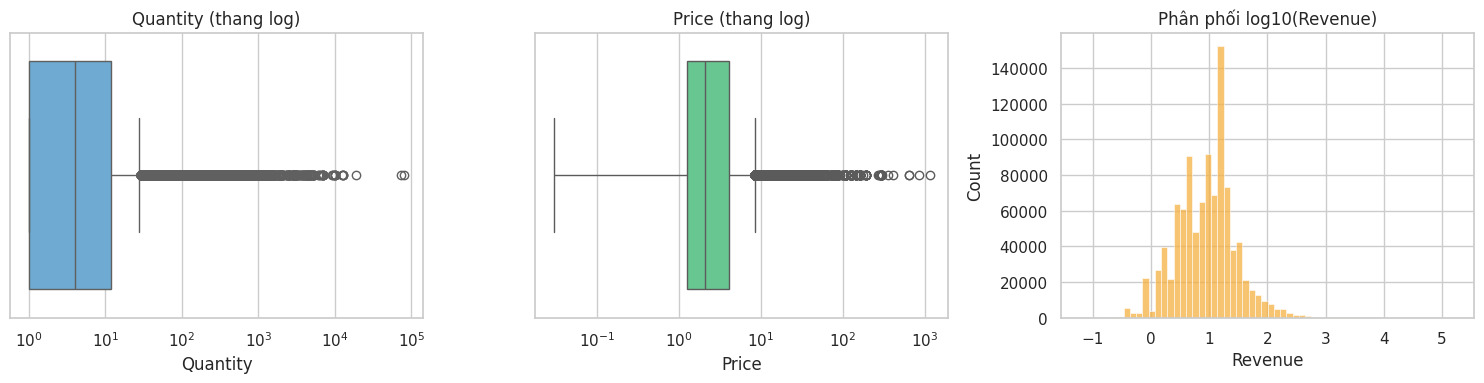

Độ lệch (skewness): Quantity = 453.2 | Price = 39.9 | Revenue = 661.8


In [ ]:
# Tạo biến doanh thu cho từng dòng
df['Revenue'] = df.Quantity * df.Price

# Trực quan phân phối Quantity & Price: boxplot (thang log vì lệch rất mạnh)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(x=df.Quantity, ax=axes[0], color='#5dade2'); axes[0].set_xscale('log'); axes[0].set_title('Quantity (thang log)')
sns.boxplot(x=df.Price, ax=axes[1], color='#58d68d'); axes[1].set_xscale('log'); axes[1].set_title('Price (thang log)')
sns.histplot(np.log10(df.Revenue), bins=60, ax=axes[2], color='#f5b041'); axes[2].set_title('Phân phối log10(Revenue)')
plt.tight_layout(); plt.show()

print('Độ lệch (skewness): Quantity = %.1f | Price = %.1f | Revenue = %.1f' % (df.Quantity.skew(), df.Price.skew(), df.Revenue.skew()))

In [ ]:
# Phương pháp IQR: đếm số điểm nằm ngoài [Q1 - 1.5*IQR, Q3 + 1.5*IQR]
def iqr_bounds(s, k=1.5):
    q1, q3 = s.quantile([.25, .75])
    return q1 - k * (q3 - q1), q3 + k * (q3 - q1)

for col in ['Quantity', 'Price', 'Revenue']:
    lo, hi = iqr_bounds(df[col])
    out = ((df[col] < lo) | (df[col] > hi))
    print(f'{col:9s}: ngưỡng trên IQR = {hi:8.2f} → {out.sum():>7,} outliers ({out.mean():.1%}), '
          f'chiếm {df.loc[out, "Revenue"].sum() / df.Revenue.sum():.1%} doanh thu')

Quantity : ngưỡng trên IQR =    28.50 →  53,019 outliers (5.3%), chiếm 36.6% doanh thu
Price    : ngưỡng trên IQR =     8.45 →  75,303 outliers (7.5%), chiếm 12.7% doanh thu
Revenue  : ngưỡng trên IQR =    38.06 →  82,399 outliers (8.2%), chiếm 50.2% doanh thu


In [ ]:
# 10 dòng có Quantity lớn nhất — đơn sỉ thật hay lỗi nhập liệu?
top_q = df.nlargest(10, 'Quantity')[['Invoice', 'StockCode', 'Description', 'Quantity', 'Price', 'Customer ID', 'InvoiceDate']]
# Đối chiếu: các giao dịch này có bị hủy lại với đúng số lượng không?
cancel_keys = set(zip(df_cancel['Customer ID'], df_cancel.StockCode, -df_cancel.Quantity))
top_q['Bị hủy lại?'] = [(c, s, q) in cancel_keys for c, s, q in zip(top_q['Customer ID'], top_q.StockCode, top_q.Quantity)]
top_q

,Invoice,StockCode,Description,Quantity,Price,Customer ID,InvoiceDate,Bị hủy lại?
1065882,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,16446,2011-12-09 09:15:00,True
587080,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,12346,2011-01-18 10:01:00,True
90857,497946,37410,BLACK AND WHITE PAISLEY FLOWER MUG,19152,0.10,13902,2010-02-15 11:57:00,False
127166,501534,21099,SET/6 STRAWBERRY PAPER CUPS,12960,0.10,13902,2010-03-17 13:09:00,False
127168,501534,21091,SET/6 WOODLAND PAPER PLATES,12960,0.10,13902,2010-03-17 13:09:00,False
127169,501534,21085,SET/6 WOODLAND PAPER CUPS,12744,0.10,13902,2010-03-17 13:09:00,False
127167,501534,21092,SET/6 STRAWBERRY PAPER PLATES,12480,0.10,13902,2010-03-17 13:09:00,False
135027,502269,21984,PACK OF 12 PINK PAISLEY TISSUES,10000,0.25,17940,2010-03-23 15:36:00,False
135028,502269,21982,PACK OF 12 SUKI TISSUES,10000,0.25,17940,2010-03-23 15:36:00,False
135029,502269,21980,PACK OF 12 RED RETROSPOT TISSUES,10000,0.25,17940,2010-03-23 15:36:00,False


In [ ]:
# IQR là công cụ phát hiện, KHÔNG mặc định xóa các đơn sỉ lớn.
# Kiểm tra 10 dòng có Quantity cao nhất và đối chiếu với hóa đơn hủy ở cell trước.
# Trong phiên bản cơ bản này giữ nguyên các giao dịch dương đã qua bước lọc.
print('Số dòng được giữ sau bước đánh giá ngoại lệ:', f'{len(df):,}')
print('Lý do: không đủ bằng chứng để kết luận mọi điểm nằm ngoài IQR đều là lỗi.')


Số dòng được giữ sau bước đánh giá ngoại lệ: 1,003,496
Lý do: không đủ bằng chứng để kết luận mọi điểm nằm ngoài IQR đều là lỗi.


## 2.2 Tạo biến (feature engineering) & tổng kết làm sạch

In [ ]:
# Tạo các biến thời gian phục vụ phân tích
df['Revenue']   = df.Quantity * df.Price
df['YearMonth'] = df.InvoiceDate.dt.to_period('M')
df['Year']      = df.InvoiceDate.dt.year
df['Month']     = df.InvoiceDate.dt.month
df['Weekday']   = df.InvoiceDate.dt.day_name()
df['Hour']      = df.InvoiceDate.dt.hour
df['IsUK']      = df.Country.eq('United Kingdom')

# Bảng có Customer ID — dùng cho phân tích khách hàng
df_cust = df.dropna(subset=['Customer ID']).copy()

summary = pd.DataFrame({
    'Dữ liệu gốc':  [len(df_raw), df_raw.Invoice.nunique(), df_raw['Customer ID'].nunique(), df_raw.StockCode.nunique()],
    'Sau làm sạch': [len(df), df.Invoice.nunique(), df['Customer ID'].nunique(), df.StockCode.nunique()],
    'Có Customer ID': [len(df_cust), df_cust.Invoice.nunique(), df_cust['Customer ID'].nunique(), df_cust.StockCode.nunique()],
}, index=['Số dòng', 'Số hóa đơn', 'Số khách hàng', 'Số sản phẩm'])
display(summary)
print(f'Tổng doanh thu thuần sau làm sạch: £{df.Revenue.sum():,.0f}')

,Dữ liệu gốc,Sau làm sạch,Có Customer ID
Số dòng,1067371,1003496,776840
Số hóa đơn,53628,39536,36613
Số khách hàng,5942,5853,5853
Số sản phẩm,5305,4712,4624


Tổng doanh thu thuần sau làm sạch: £19,657,090


---
# GIAI ĐOẠN 3 — Phân tích, kiểm định giả thuyết và trực quan hóa

**Câu hỏi nghiên cứu:** (1) Doanh thu biến động thế nào theo thời gian? (2) Doanh thu tập trung vào nhóm khách hàng nào? (3) Thị trường và sản phẩm nào đóng góp lớn? (4) Đơn hàng phân bố ra sao theo ngày/giờ?

- **H1 (mô tả):** Doanh thu có khác biệt theo mùa/tháng; dùng biểu đồ và tỷ trọng, **không khẳng định ý nghĩa thống kê**.
- **H2 (mô tả):** Doanh thu tập trung vào một tỷ lệ nhỏ khách hàng; dùng đường Pareto.
- **H3 (mô tả):** Giá trị đơn hàng khác nhau giữa UK và quốc tế; dùng boxplot và thống kê nhóm.
- **H4 (kiểm định):** Trong các ngày làm việc thứ Hai–thứ Sáu, số hóa đơn có phân bố đều không? Dùng Chi-square goodness-of-fit, mức ý nghĩa 5%.

**Giải thích:** H1–H3 là giả thuyết nghiên cứu được đánh giá bằng thống kê mô tả, không phải kiểm định suy luận. Chỉ H4 có p-value; p-value nhỏ không chứng minh nguyên nhân hay tính đồng đều của lưu lượng khách theo từng ngày.


## 3.1 H1 — Xu hướng & tính mùa vụ của doanh thu (Line chart)

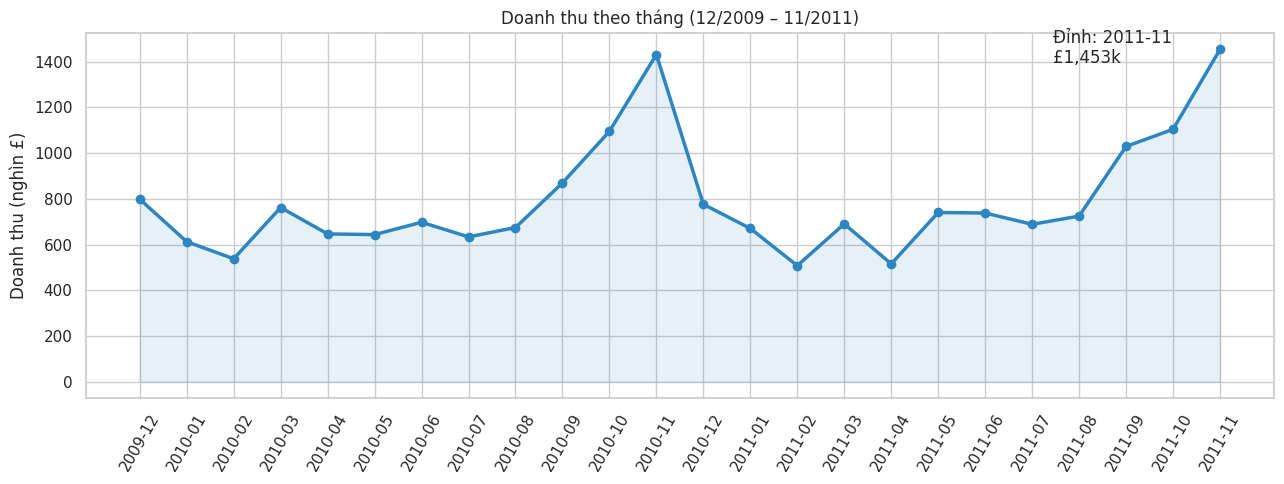

,Revenue,Orders,Customers,AOV
YearMonth,,,,
2010-12,"776,172.23",1551,884,500.43
2011-01,"670,561.99",1081,739,620.32
2011-02,"507,998.42",1093,757,464.77
2011-03,"690,458.49",1440,973,479.49
2011-04,"515,754.78",1235,853,417.62
2011-05,"740,350.35",1668,1054,443.86
2011-06,"738,108.98",1525,990,484.01
2011-07,"688,694.79",1452,946,474.31
2011-08,"724,596.76",1340,933,540.74


In [ ]:
# Doanh thu, số hóa đơn và số khách theo tháng
monthly = df.groupby('YearMonth').agg(Revenue=('Revenue', 'sum'),
                                      Orders=('Invoice', 'nunique'),
                                      Customers=('Customer ID', 'nunique'))
monthly = monthly.iloc[:-1]   # bỏ 12/2011 vì chỉ có dữ liệu đến ngày 9 (tháng không đầy đủ)
monthly['AOV'] = monthly.Revenue / monthly.Orders

fig, ax = plt.subplots(figsize=(13, 5))
x = monthly.index.astype(str)
ax.plot(x, monthly.Revenue / 1e3, marker='o', lw=2.5, color='#2e86c1')
ax.fill_between(x, monthly.Revenue / 1e3, alpha=.12, color='#2e86c1')
ax.set_title('Doanh thu theo tháng (12/2009 – 11/2011)'); ax.set_ylabel('Doanh thu (nghìn £)')
peak = monthly.Revenue.idxmax()
ax.annotate(f'Đỉnh: {peak}\n£{monthly.Revenue.max()/1e3:,.0f}k', xy=(str(peak), monthly.Revenue.max()/1e3),
            xytext=(-120, -10), textcoords='offset points', arrowprops=dict(arrowstyle='->'))
plt.xticks(rotation=60); plt.tight_layout(); plt.show()
monthly.tail(12)

In [ ]:
# Kiểm chứng định lượng H1: tỷ trọng doanh thu từng quý trong năm 2010 (năm dương lịch duy nhất có đủ 12 tháng)
df_q = df[df.Year == 2010].copy()
df_q['Quarter'] = 'Q' + df_q.InvoiceDate.dt.quarter.astype(str)
q_share = df_q.groupby('Quarter').Revenue.sum()
print('Tỷ trọng doanh thu theo quý năm 2010 (%):'); print((q_share / q_share.sum() * 100).round(1))

# So sánh doanh thu trung bình tháng: Sep–Nov vs các tháng khác
m = monthly.copy(); m['Peak'] = m.index.month.isin([9, 10, 11])
print('Doanh thu TB/tháng (nghìn £):'); print((m.groupby('Peak').Revenue.mean() / 1e3).rename({True: 'Tháng 9–11', False: 'Các tháng khác'}))
# Tăng trưởng năm 2 so với năm 1 (cùng kỳ 12 tháng)
y1 = monthly.loc['2009-12':'2010-11'].Revenue.sum(); y2 = monthly.loc['2010-12':'2011-11'].Revenue.sum()
print(f'Doanh thu 12/09–11/10: £{y1:,.0f} | 12/10–11/11: £{y2:,.0f} | tăng trưởng: {y2/y1-1:+.1%}')

Tỷ trọng doanh thu theo quý năm 2010 (%):
Quarter
Q1   20.40
Q2   21.20
Q3   23.20
Q4   35.20
Name: Revenue, dtype: float64
Doanh thu TB/tháng (nghìn £):
Peak
Các tháng khác     670.01
Tháng 9–11       1,163.72
Name: Revenue, dtype: float64
Doanh thu 12/09–11/10: £9,403,218 | 12/10–11/11: £9,639,184 | tăng trưởng: +2.5%


**📌 Cách diễn giải H1:** So sánh doanh thu trung bình tháng 9–11 với các tháng khác và tỷ trọng từng quý của năm 2010. Nếu cao hơn, kết luận *dữ liệu quan sát cho thấy dấu hiệu mùa vụ*, không nói đã chứng minh quy luật cho các năm tiếp theo. Năm 2009 và 2011 không có đủ tháng ở hai đầu chuỗi; cell đã loại tháng 12/2011 chưa đầy đủ. Nên đối chiếu trực tiếp output thay vì dùng các số cố định trong notebook cũ.


## 3.2 Thị trường: doanh thu theo quốc gia (Bar chart)

UK chiếm 85.5% doanh thu, 91.1% số khách hàng


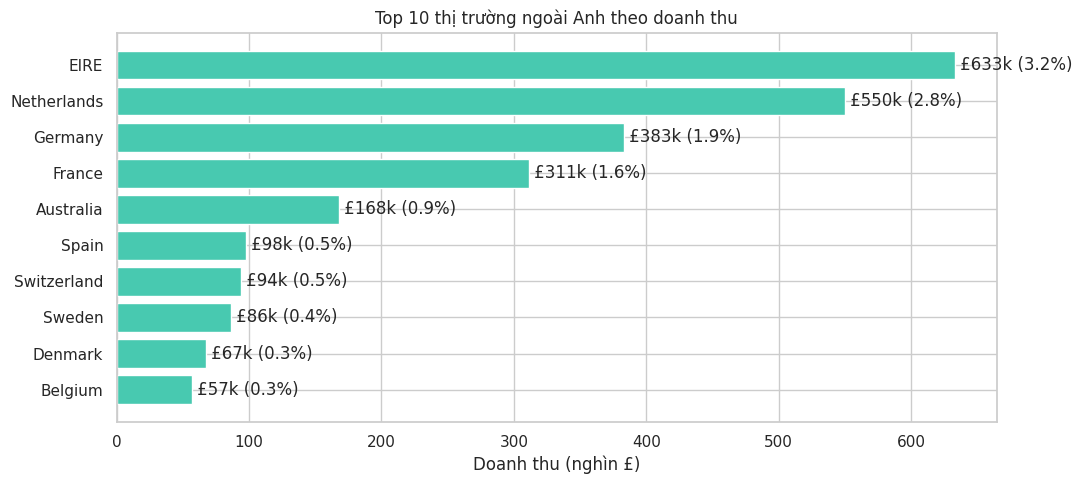

In [ ]:
# Top 10 quốc gia theo doanh thu, ngoài UK
country = df.groupby('Country').agg(Revenue=('Revenue', 'sum'), Customers=('Customer ID', 'nunique'), Orders=('Invoice', 'nunique'))
country['Share (%)'] = country.Revenue / country.Revenue.sum() * 100
print(f"UK chiếm {country.loc['United Kingdom', 'Share (%)']:.1f}% doanh thu, "
      f"{country.loc['United Kingdom', 'Customers'] / df['Customer ID'].nunique():.1%} số khách hàng")

top_c = country.drop('United Kingdom').nlargest(10, 'Revenue')
fig, ax = plt.subplots(figsize=(11, 5))
ax.barh(top_c.index[::-1], top_c.Revenue[::-1] / 1e3, color='#48c9b0')
for i, (v, s) in enumerate(zip(top_c.Revenue[::-1] / 1e3, top_c['Share (%)'][::-1])):
    ax.text(v, i, f' £{v:,.0f}k ({s:.1f}%)', va='center')
ax.set_title('Top 10 thị trường ngoài Anh theo doanh thu'); ax.set_xlabel('Doanh thu (nghìn £)')
plt.tight_layout(); plt.show()

## 3.3 H3 — Khách quốc tế có giá trị đơn hàng (AOV) cao hơn khách Anh?

/tmp/ipykernel_653/318679001.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=orders, x='Thị trường', y='Revenue', ax=ax, showfliers=False, palette=['#5dade2', '#f5b041'])


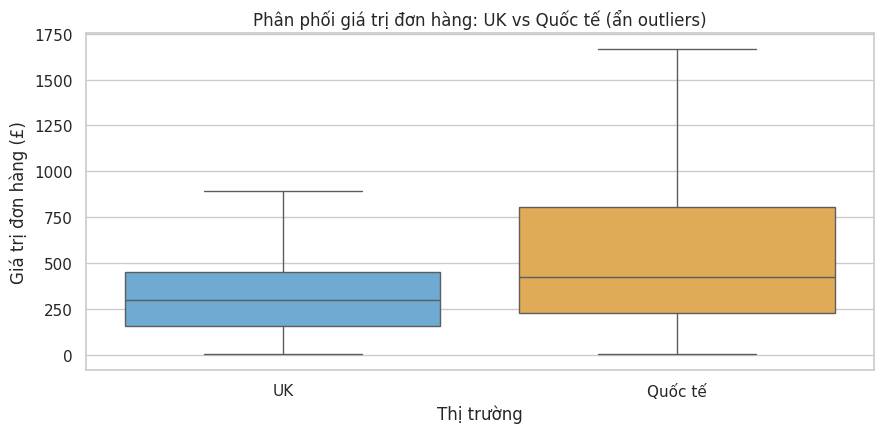

               count   mean    50%
Thị trường                        
Quốc tế     3,239.00 861.22 423.90
UK         33,374.00 428.26 299.47


In [ ]:
# Giá trị từng hóa đơn
orders = df_cust.groupby(['Invoice', 'IsUK']).Revenue.sum().reset_index()
orders['Thị trường'] = orders.IsUK.map({True: 'UK', False: 'Quốc tế'})

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.boxplot(data=orders, x='Thị trường', y='Revenue', ax=ax, showfliers=False, palette=['#5dade2', '#f5b041'])
ax.set_title('Phân phối giá trị đơn hàng: UK vs Quốc tế (ẩn outliers)'); ax.set_ylabel('Giá trị đơn hàng (£)')
plt.tight_layout(); plt.show()

print(orders.groupby('Thị trường').Revenue.describe()[['count', 'mean', '50%']])


## 3.4 H4 — Thời điểm mua hàng (Heatmap ngày × giờ)

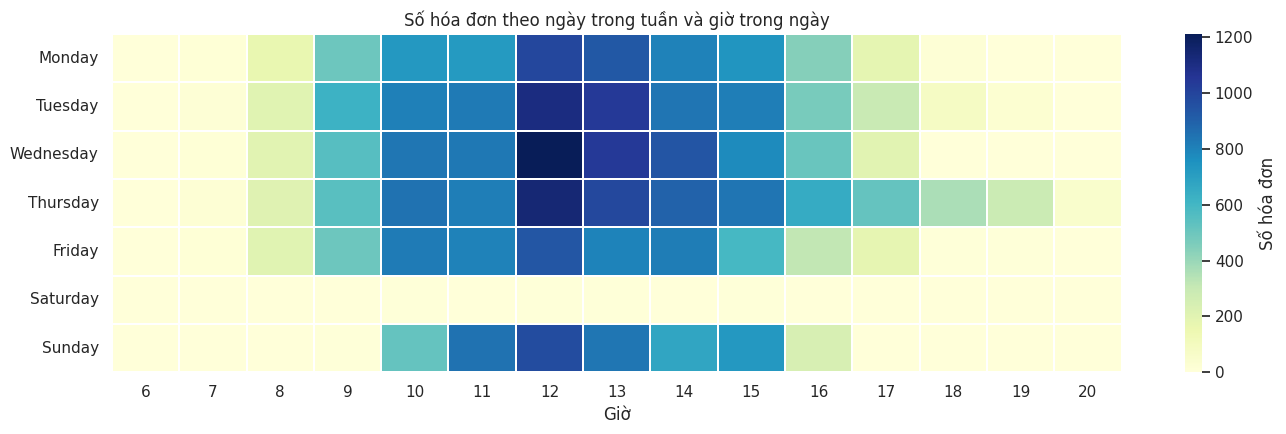

Tỷ trọng hóa đơn theo ngày (%):
Weekday
Monday      15.80
Tuesday     18.10
Wednesday   18.00
Thursday    20.70
Friday      15.20
Saturday     0.10
Sunday      12.20
dtype: float64

Chi-square (đồng đều giữa T2–T6): chi2 = 425.6, p-value = 8.17e-91


In [ ]:
# Số hóa đơn theo ngày trong tuần x giờ
order_days = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
inv_time = df.drop_duplicates('Invoice')
heat = inv_time.pivot_table(index='Weekday', columns='Hour', values='Invoice', aggfunc='count').reindex(order_days).fillna(0)

fig, ax = plt.subplots(figsize=(14, 4.5))
sns.heatmap(heat, cmap='YlGnBu', ax=ax, cbar_kws={'label': 'Số hóa đơn'}, linewidths=.3)
ax.set_title('Số hóa đơn theo ngày trong tuần và giờ trong ngày'); ax.set_xlabel('Giờ'); ax.set_ylabel('')
plt.tight_layout(); plt.show()

print('Tỷ trọng hóa đơn theo ngày (%):'); print((heat.sum(axis=1) / heat.values.sum() * 100).round(1))
# Kiểm định chi-square: số đơn có phân bố đều giữa các ngày làm việc (Thứ 2–Thứ 6) không?
obs = heat.sum(axis=1).loc[order_days[:5]]
chi2, p = stats.chisquare(obs)
print(f'\nChi-square (đồng đều giữa T2–T6): chi2 = {chi2:,.1f}, p-value = {p:.2e}')

## 3.5 Sản phẩm bán chạy & tỷ lệ hủy đơn

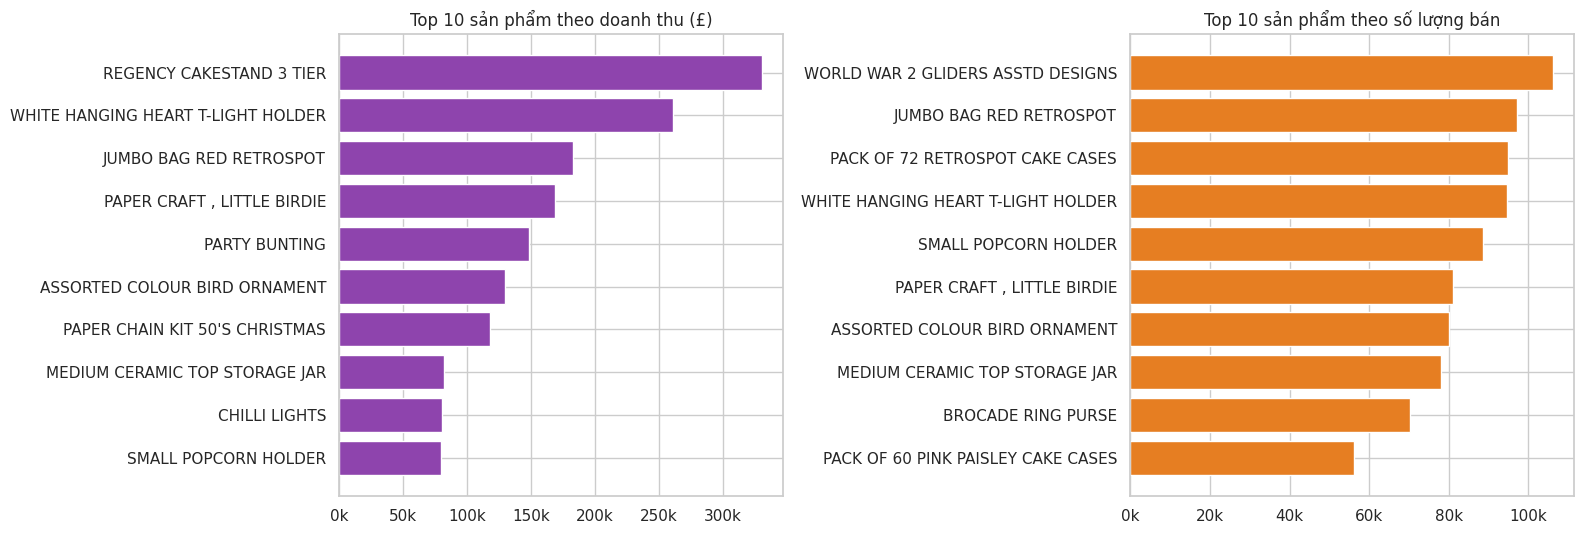

Số sản phẩm: 4,675 | 20% sản phẩm hàng đầu tạo ra 77.9% doanh thu


In [ ]:
# Top 10 sản phẩm theo doanh thu và theo số lượng
prod = df.groupby('Description').agg(Revenue=('Revenue', 'sum'), Quantity=('Quantity', 'sum'), Orders=('Invoice', 'nunique'))
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
for ax, col, color in zip(axes, ['Revenue', 'Quantity'], ['#8e44ad', '#e67e22']):
    t = prod.nlargest(10, col)[col][::-1]
    ax.barh(t.index.str[:35], t.values, color=color)
    ax.set_title(f'Top 10 sản phẩm theo {"doanh thu (£)" if col=="Revenue" else "số lượng bán"}')
    ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f'{v/1e3:,.0f}k'))
plt.tight_layout(); plt.show()

top20_share = prod.Revenue.nlargest(int(len(prod) * .2)).sum() / prod.Revenue.sum()
print(f'Số sản phẩm: {len(prod):,} | 20% sản phẩm hàng đầu tạo ra {top20_share:.1%} doanh thu')

In [ ]:
# Tỷ lệ hủy đơn theo thị trường (dựa trên bảng hóa đơn hủy đã tách ở Giai đoạn 2)
n_order = df.groupby(df.IsUK).Invoice.nunique()
n_cancel = df_cancel.groupby(df_cancel.Country.eq('United Kingdom')).Invoice.nunique()
rate = (n_cancel / (n_order + n_cancel) * 100).rename({True: 'UK', False: 'Quốc tế'})
print('Tỷ lệ hóa đơn bị hủy (%):'); print(rate.round(2))
print(f'Giá trị hàng bị hủy/trả: £{-(df_cancel.Quantity * df_cancel.Price).sum():,.0f} '
      f'({-(df_cancel.Quantity * df_cancel.Price).sum() / df.Revenue.sum():.1%} doanh thu thuần)')

Tỷ lệ hóa đơn bị hủy (%):
Country
Quốc tế   22.64
UK        16.81
Name: Invoice, dtype: float64
Giá trị hàng bị hủy/trả: £1,462,051 (7.4% doanh thu thuần)


## 3.6 H2 — Doanh thu có tập trung vào số ít khách hàng? (Đường Pareto)

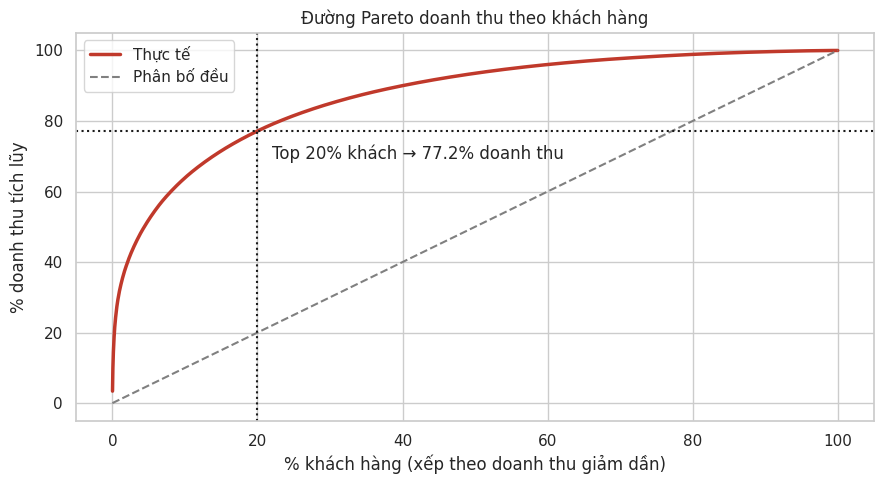

1,353 khách (23.1%) tạo ra 80% doanh thu có định danh
Top 10 khách hàng chiếm 16.2% doanh thu


In [ ]:
# Đường cong tích lũy doanh thu theo khách hàng (sắp xếp giảm dần)
cust_rev = df_cust.groupby('Customer ID').Revenue.sum().sort_values(ascending=False)
cum = cust_rev.cumsum() / cust_rev.sum()
pct_cust = np.arange(1, len(cum) + 1) / len(cum)

share_top20 = cum.iloc[int(len(cum) * .2) - 1]
n_for_80 = (cum < .8).sum() + 1

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(pct_cust * 100, cum.values * 100, lw=2.5, color='#c0392b', label='Thực tế')
ax.plot([0, 100], [0, 100], '--', color='grey', label='Phân bố đều')
ax.axvline(20, ls=':', color='k'); ax.axhline(share_top20 * 100, ls=':', color='k')
ax.text(22, share_top20 * 100 - 8, f'Top 20% khách → {share_top20:.1%} doanh thu')
ax.set_xlabel('% khách hàng (xếp theo doanh thu giảm dần)'); ax.set_ylabel('% doanh thu tích lũy')
ax.set_title('Đường Pareto doanh thu theo khách hàng'); ax.legend(); plt.tight_layout(); plt.show()

print(f'{n_for_80:,} khách ({n_for_80/len(cum):.1%}) tạo ra 80% doanh thu có định danh')
print(f'Top 10 khách hàng chiếm {cust_rev.head(10).sum() / cust_rev.sum():.1%} doanh thu')

---
# GIAI ĐOẠN 4 — Đánh giá tác động, khuyến nghị và giới hạn

**Mục đích:** Trả lời câu hỏi *phân tích này giúp ra quyết định gì?* Mỗi phát hiện cần gắn với một phép tính/biểu đồ cụ thể, một hàm ý kinh doanh và một giới hạn diễn giải. Không sử dụng kết luận từ K-Means, FP-Growth hay Cohort vì đã bỏ các mô hình đó.


In [ ]:
# Bảng kết quả tự tính từ dữ liệu sau làm sạch: dùng cho báo cáo và kiểm tra kết luận
summary_results = pd.DataFrame([
    ['Số dòng sau làm sạch', len(df), 'df'],
    ['Số hóa đơn bán hàng', df.Invoice.nunique(), 'df.Invoice'],
    ['Doanh thu dòng bán hàng (£)', df.Revenue.sum(), 'df.Revenue'],
    ['Số khách có định danh', df_cust['Customer ID'].nunique(), 'df_cust'],
    ['Tỷ trọng doanh thu UK (%)', country.loc['United Kingdom','Share (%)'], 'country'],
    ['Tỷ trọng doanh thu top 20% khách (%)', share_top20 * 100, 'cust_rev'],
    ['Số khách chiếm 80% doanh thu', n_for_80, 'cust_rev'],
    ['p-value Chi-square T2–T6', p, 'stats.chisquare'],
], columns=['Chỉ số', 'Giá trị', 'Nguồn tính'])
display(summary_results)
print('Trung bình doanh thu tháng 9–11 và các tháng khác (£):')
display(m.groupby('Peak').Revenue.mean().rename({True:'Tháng 9–11',False:'Tháng khác'}))
print('Giá trị đơn hàng theo thị trường (£):')
display(orders.groupby('Thị trường').Revenue.agg(['count','mean','median']))


,Chỉ số,Giá trị,Nguồn tính
0,Số dòng sau làm sạch,"1,003,496.00",df
1,Số hóa đơn bán hàng,"39,536.00",df.Invoice
2,Doanh thu dòng bán hàng (£),"19,657,089.95",df.Revenue
3,Số khách có định danh,"5,853.00",df_cust
4,Tỷ trọng doanh thu UK (%),85.48,country
5,Tỷ trọng doanh thu top 20% khách (%),77.16,cust_rev
6,Số khách chiếm 80% doanh thu,"1,353.00",cust_rev
7,p-value Chi-square T2–T6,0.00,stats.chisquare


Trung bình doanh thu tháng 9–11 và các tháng khác (£):


,Revenue
Peak,
Tháng khác,"670,005.53"
Tháng 9–11,"1,163,717.13"


Giá trị đơn hàng theo thị trường (£):


,count,mean,median
Thị trường,,,
Quốc tế,3239,861.22,423.90
UK,33374,428.26,299.47


## 4.1. Tổng hợp câu hỏi nghiên cứu và bằng chứng

| Câu hỏi | Bằng chứng cần trích từ kết quả | Cách kết luận đúng |
|---|---|---|
| H1 — Biến động doanh thu theo mùa | Line chart `monthly`, bảng `q_share`, trung bình nhóm `Peak` | Mô tả mức chênh lệch; không tuyên bố đã kiểm định mùa vụ |
| H2 — Mức tập trung doanh thu khách hàng | `share_top20`, `n_for_80`, đường Pareto | Chỉ áp dụng cho khách có mã định danh |
| H3 — UK và quốc tế có khác biệt về AOV? | `orders.groupby(...).describe()` và boxplot | So sánh trung bình/trung vị; không khẳng định ý nghĩa thống kê |
| H4 — Số đơn T2–T6 phân bố đều? | Chi-square và `p` ở cell 3.4 | Bác bỏ hoặc chưa bác bỏ H0 theo ngưỡng 0,05; không suy ra nguyên nhân |

**Không sao chép các con số cố định của notebook gốc.** Sau khi chạy, thay bằng số trong bảng kết quả ở cell ngay trên, có thể chụp hoặc xuất bảng sang báo cáo PDF.

## 4.2. Phát hiện kinh doanh và ý nghĩa

**A. Xu hướng doanh thu theo thời gian.** Biểu đồ đường và bảng doanh thu theo quý cho thấy tháng/quý nào có doanh thu lớn hơn. Nếu tháng 9–11 cao hơn rõ rệt, đây là tín hiệu để chuẩn bị tồn kho và năng lực xử lý đơn trước mùa cao điểm. **Giới hạn:** hai đầu chuỗi không đủ tháng; sự lặp lại qua nhiều năm chưa được chứng minh.

**B. Cơ cấu thị trường.** Bảng `country` xác định tỷ trọng doanh thu UK và các thị trường ngoài UK. Doanh thu cao không đồng nghĩa lợi nhuận cao vì chưa có dữ liệu vận chuyển, giá vốn, thuế hoặc chi phí chăm sóc khách hàng. Nên xem thị trường quốc tế như cơ hội cần thẩm định thêm, không tự động kết luận phải mở rộng.

**C. Cơ cấu sản phẩm.** Bảng `prod` cho biết sản phẩm có doanh thu và số lượng bán lớn. Hai chỉ tiêu trả lời câu hỏi khác nhau: bán nhiều đơn vị chưa chắc tạo doanh thu lớn nhất. Có thể dùng để ưu tiên kiểm soát tồn kho, nhưng cần đối chiếu biên lợi nhuận trước khi quyết định nhập hàng.

**D. Sự tập trung doanh thu khách hàng.** Đường Pareto cho thấy phần doanh thu do nhóm khách hàng lớn đóng góp. Nếu tập trung cao, cần vừa chăm sóc nhóm này vừa giảm rủi ro phụ thuộc bằng cách phát triển khách hàng khác. **Giới hạn:** phân tích chỉ tính các khách có `Customer ID`.

**E. Thời gian đặt hàng và kiểm định.** Heatmap mô tả giờ/ngày nhiều hóa đơn; kiểm định Chi-square đánh giá liệu số đơn T2–T6 có đồng đều theo giả định hay không. Nếu bác bỏ H0, có thể cân nhắc bố trí nhân lực theo mức tải quan sát được, nhưng cần kiểm tra lịch mở cửa/ngày nghỉ trước khi áp dụng.

**F. Hủy/trả hàng.** `df_cancel` được tách riêng để mô tả số hóa đơn hủy và giá trị dòng âm. Chỉ số hủy không phải là tỷ lệ hoàn tiền chính xác vì chưa ghép toàn bộ hóa đơn hủy với hóa đơn gốc. Tránh gọi doanh thu dòng dương là *doanh thu thuần sau hoàn trả*.

## 4.3. Khuyến nghị có điều kiện và cách kiểm chứng

| Phát hiện từ phân tích | Đề xuất | Cách đo hiệu quả sau triển khai |
|---|---|---|
| Doanh thu tập trung ở một số tháng | Chuẩn bị hàng và nhân lực trước tháng cao điểm | Tỷ lệ hết hàng, thời gian xử lý đơn, doanh thu theo tháng |
| Nhóm khách đóng góp doanh thu lớn | Chăm sóc khách giá trị cao, đồng thời đa dạng hóa tệp khách | Tỷ lệ mua lại, tỷ trọng doanh thu top khách |
| Một số mặt hàng đóng góp lớn | Ưu tiên dự báo nhu cầu và kiểm soát tồn kho | Số ngày hết hàng, vòng quay tồn kho |
| Thị trường ngoài UK có tiềm năng | Thử nghiệm quy mô nhỏ sau khi tính chi phí logistics | Lợi nhuận gộp, tỷ lệ trả hàng, chi phí giao hàng |
| Một số khung giờ có nhiều đơn | Điều chỉnh ca trực dựa trên lịch mở cửa thực tế | Thời gian xử lý đơn, số đơn/nhân sự |
| Có hóa đơn hủy/trả | Rà soát nguyên nhân và ghép đơn gốc với đơn trả | Tỷ lệ hoàn trả đúng nghĩa, nguyên nhân trả hàng |



## 4.4. Giới hạn của nghiên cứu

1. `Customer ID` thiếu ở nhiều dòng: phân tích theo khách chỉ áp dụng cho phần có định danh; không được suy diễn trực tiếp cho toàn bộ khách.
2. Dữ liệu là giao dịch của một doanh nghiệp trong giai đoạn 2009–2011: không đại diện cho toàn bộ thương mại điện tử hiện nay.
3. Không có giá vốn, vận chuyển, marketing hay tồn kho: chỉ đánh giá doanh thu và số lượng, không tính được lợi nhuận hoặc hiệu quả chiến dịch.
4. Dữ liệu có hóa đơn hủy, mã điều chỉnh và các dòng có thể trùng: kết quả phụ thuộc quy tắc lọc; loại dòng trùng hoàn toàn có thể xóa cả các dòng trùng hợp lệ.
5. Hai sheet có giai đoạn thời gian giao nhau; cần kiểm tra rủi ro trùng dữ liệu. Tháng 12/2011 không đầy đủ nên không dùng trong chuỗi tháng so sánh.
6. Kiểm định Chi-square giả định các quan sát phù hợp và số kỳ vọng đủ lớn; việc phân bố không đều không cho biết nguyên nhân.
7. Phân tích mô tả không chứng minh quan hệ nhân quả; các khuyến nghị cần dữ liệu bổ sung và thử nghiệm thực tế.




